In [1]:
!pip install -q datasets pandas pyarrow scikit-learn

In [2]:
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import os

# Load complete Asclepius dataset
dataset = load_dataset(
    "starmpcc/Asclepius-Synthetic-Clinical-Notes",
    split="train"
)

df = dataset.to_pandas()

print("Original dataset:", len(df))
print("\nAvailable columns:", df.columns.tolist())

# Inspect task distribution (audit only)
print("\nTask distribution:")
print(df["task"].value_counts())

# Keep only required training fields
# answer is necessary as the supervised training target
df = df[["patient_id", "note", "question", "answer"]].copy()

# Clean missing and empty records
for col in ["note", "question", "answer"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df = df[
    (df["note"] != "") &
    (df["question"] != "") &
    (df["answer"] != "") &
    (df["patient_id"].notna())
].copy()

# Remove exact duplicate training examples
df.drop_duplicates(
    subset=["patient_id", "note", "question", "answer"],
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("\nClean dataset:", len(df))

# Group-based splitting to prevent patient leakage
groups = df["patient_id"].values

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.02,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(df, groups=groups)
)

train_val = df.iloc[train_val_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.010204,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["patient_id"].values)
)

train = train_val.iloc[train_idx].reset_index(drop=True)
val = train_val.iloc[val_idx].reset_index(drop=True)

# Verify patient separation
assert set(train.patient_id).isdisjoint(set(val.patient_id))
assert set(train.patient_id).isdisjoint(set(test.patient_id))
assert set(val.patient_id).isdisjoint(set(test.patient_id))

# Save
OUTPUT_DIR = "/content/drive/MyDrive/clinical_summarizer/prepared_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

train.to_parquet(f"{OUTPUT_DIR}/train.parquet", index=False)
val.to_parquet(f"{OUTPUT_DIR}/validation.parquet", index=False)
test.to_parquet(f"{OUTPUT_DIR}/test.parquet", index=False)

print("\nDataset preparation completed!")
print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))
print("Saved to:", OUTPUT_DIR)

README.md:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

synthetic.csv: reconstructing file:   0%|          |  0.00B /  402MB            

synthetic.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/158114 [00:00<?, ? examples/s]

Original dataset: 158114

Available columns: ['patient_id', 'note', 'question', 'answer', 'task']

Task distribution:
task
Question Answering                 20038
Abbreviation Expansion             20015
Relation Extraction                19926
Named Entity Recognition           19848
Summarization                      19756
Temporal Information Extraction    19654
Coreference Resolution             19622
Paraphrasing                       19255
Name: count, dtype: int64

Clean dataset: 158114

Dataset preparation completed!
Training: 153369
Validation: 1582
Testing: 3163
Saved to: /content/drive/MyDrive/clinical_summarizer/prepared_data


In [ ]:
import os

print("Drive directory exists:", os.path.exists("/content/drive"))
print("Already mounted:", os.path.ismount("/content/drive"))

if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive")[:10])

Drive directory exists: True
Already mounted: False
['MyDrive']


In [ ]:
OUTPUT_DIR = "/content/gdrive/MyDrive/clinical_summarizer/prepared_data"

In [3]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "starmpcc/Asclepius-Synthetic-Clinical-Notes",
    split="train"
)

df = dataset.to_pandas()

print("Total records:", len(df))
print("\nColumns:", df.columns.tolist())

print("\nTask distribution:")
print(df["task"].value_counts())

print("\nSample record:")
display(df[["patient_id", "note", "question", "answer", "task"]].head(2))

Total records: 158114

Columns: ['patient_id', 'note', 'question', 'answer', 'task']

Task distribution:
task
Question Answering                 20038
Abbreviation Expansion             20015
Relation Extraction                19926
Named Entity Recognition           19848
Summarization                      19756
Temporal Information Extraction    19654
Coreference Resolution             19622
Paraphrasing                       19255
Name: count, dtype: int64

Sample record:


,patient_id,note,question,answer,task
0,0,Discharge Summary:\n\nPatient: 60-year-old mal...,Can you provide a simplified paraphrase of the...,The healthcare team used a gradual approach to...,Paraphrasing
1,1,Discharge Summary:\n\nAdmission Date: [Insert ...,Which coreferences were resolved in the hospit...,The hospital course section resolved the coref...,Coreference Resolution


In [4]:
df = df[["patient_id", "note", "question", "answer"]].copy()

for col in ["note", "question", "answer"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df = df[
    (df["patient_id"].notna()) &
    (df["note"] != "") &
    (df["question"] != "") &
    (df["answer"] != "")
].copy()

df.drop_duplicates(
    subset=["patient_id", "note", "question", "answer"],
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("Clean records:", len(df))
display(df.head(3))

Clean records: 158114


,patient_id,note,question,answer
0,0,Discharge Summary:\n\nPatient: 60-year-old mal...,Can you provide a simplified paraphrase of the...,The healthcare team used a gradual approach to...
1,1,Discharge Summary:\n\nAdmission Date: [Insert ...,Which coreferences were resolved in the hospit...,The hospital course section resolved the coref...
2,2,Hospital Course Summary:\n\nAdmission Date: [I...,What were the key improvements in the patient'...,"During the hospital course, the patient's medi..."


In [6]:
from sklearn.model_selection import GroupShuffleSplit

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.02,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(df, groups=df["patient_id"])
)

train_val = df.iloc[train_val_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.010204,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["patient_id"])
)

train = train_val.iloc[train_idx].reset_index(drop=True)
val = train_val.iloc[val_idx].reset_index(drop=True)

assert set(train.patient_id).isdisjoint(set(val.patient_id))
assert set(train.patient_id).isdisjoint(set(test.patient_id))
assert set(val.patient_id).isdisjoint(set(test.patient_id))

print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))
print("Patient leakage: NONE")

Training: 153369
Validation: 1582
Testing: 3163
Patient leakage: NONE


In [7]:
import os

OUTPUT_DIR = "/content/gdrive/MyDrive/clinical_summarizer/prepared_data"

os.makedirs(OUTPUT_DIR, exist_ok=True)

train.to_parquet(f"{OUTPUT_DIR}/train.parquet", index=False)
val.to_parquet(f"{OUTPUT_DIR}/validation.parquet", index=False)
test.to_parquet(f"{OUTPUT_DIR}/test.parquet", index=False)

print("All datasets saved successfully!")

All datasets saved successfully!


In [8]:
from huggingface_hub import notebook_login

notebook_login(skip_if_logged_in=False)

In [9]:
from transformers import AutoTokenizer

MODEL_ID = "google/medgemma-4b-it"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=True
)

print("Tokenizer loaded successfully!")

config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [10]:
import numpy as np
import pandas as pd

def count_tokens(row):
    text = (
        "Clinical Note:\n" + str(row["note"]) +
        "\n\nQuestion:\n" + str(row["question"])
    )

    return len(
        tokenizer(
            text,
            add_special_tokens=True
        )["input_ids"]
    )

train["input_tokens"] = train.apply(count_tokens, axis=1)
train["answer_tokens"] = train["answer"].apply(
    lambda x: len(tokenizer(str(x))["input_ids"])
)

print("INPUT TOKEN DISTRIBUTION")
print(train["input_tokens"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nANSWER TOKEN DISTRIBUTION")
print(train["answer_tokens"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

INPUT TOKEN DISTRIBUTION
count    153369.000000
mean        440.749226
std         120.564141
min         199.000000
50%         426.000000
75%         510.000000
90%         599.000000
95%         660.000000
99%         795.000000
max        1273.000000
Name: input_tokens, dtype: float64

ANSWER TOKEN DISTRIBUTION
count    153369.000000
mean         78.397623
std          40.124328
min           7.000000
50%          73.000000
75%         101.000000
90%         130.000000
95%         151.000000
99%         199.000000
max         499.000000
Name: answer_tokens, dtype: float64


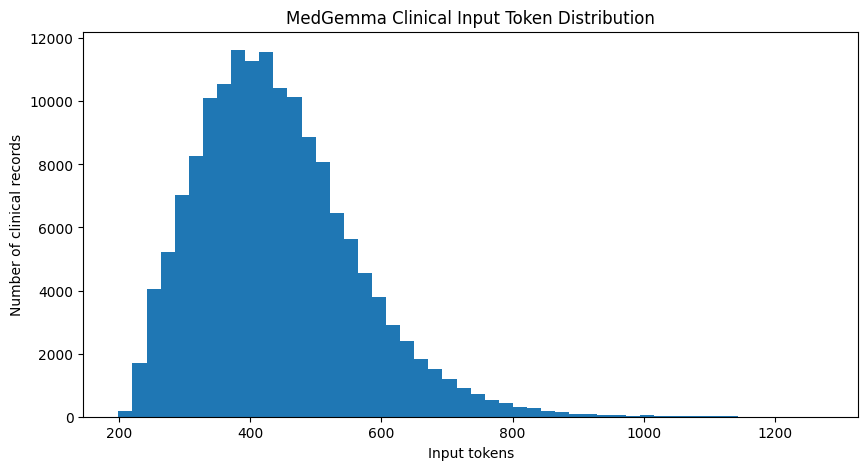

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    train["input_tokens"],
    bins=50
)

plt.xlabel("Input tokens")
plt.ylabel("Number of clinical records")
plt.title("MedGemma Clinical Input Token Distribution")

plt.show()

In [12]:
percentiles = train["input_tokens"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Recommended context analysis:")
print(percentiles)

print("\nRecords exceeding different context lengths:")

for limit in [1024, 2048, 4096, 8192]:
    count = (train["input_tokens"] > limit).sum()

    print(
        f"{limit} tokens: {count} records "
        f"({count / len(train) * 100:.2f}%)"
    )

Recommended context analysis:
0.50    426.0
0.75    510.0
0.90    599.0
0.95    660.0
0.99    795.0
Name: input_tokens, dtype: float64

Records exceeding different context lengths:
1024 tokens: 103 records (0.07%)
2048 tokens: 0 records (0.00%)
4096 tokens: 0 records (0.00%)
8192 tokens: 0 records (0.00%)


In [13]:
def get_full_sequence_length(row):

    messages = [
        {
            "role": "user",
            "content": (
                "Clinical Note:\n"
                + str(row["note"])
                + "\n\nQuestion:\n"
                + str(row["question"])
            )
        },
        {
            "role": "assistant",
            "content": str(row["answer"])
        }
    ]

    encoded = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True
    )

    return len(encoded["input_ids"][0]) if hasattr(
        encoded["input_ids"][0], "__len__"
    ) else len(encoded["input_ids"])

In [14]:
sample = train.sample(
    n=min(10000, len(train)),
    random_state=42
).copy()

sample["full_sequence_tokens"] = sample.apply(
    get_full_sequence_length,
    axis=1
)

print(sample["full_sequence_tokens"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

for limit in [1024, 1536, 2048, 4096]:
    count = (sample["full_sequence_tokens"] > limit).sum()

    print(
        f"{limit} tokens: {count} records "
        f"({count / len(sample) * 100:.2f}%)"
    )

count    10000.000000
mean       528.130800
std        135.022056
min        250.000000
50%        511.000000
75%        609.000000
90%        709.000000
95%        776.050000
99%        911.000000
max       1193.000000
Name: full_sequence_tokens, dtype: float64
1024 tokens: 27 records (0.27%)
1536 tokens: 0 records (0.00%)
2048 tokens: 0 records (0.00%)
4096 tokens: 0 records (0.00%)


In [15]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [16]:
pip install bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 57.0 MB/s  0:00:00


In [17]:
import torch
import transformers
import peft
import bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
PEFT: 0.21.2
BitsAndBytes: 0.50.2
CUDA: True


In [18]:
from transformers import BitsAndBytesConfig

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("4-bit quantization configured!")

4-bit quantization configured!


In [19]:
from transformers import AutoModelForImageTextToText

MODEL_ID = "google/medgemma-4b-it"

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
)

model.config.use_cache = False

print("MedGemma loaded successfully!")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

MedGemma loaded successfully!


In [20]:
from peft import (
    LoraConfig,
    prepare_model_for_kbit_training,
    get_peft_model
)

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 16,394,240 || all params: 4,316,473,712 || trainable%: 0.3798


In [21]:
MAX_LENGTH = 1536

print("Maximum training sequence:", MAX_LENGTH)
print("Training examples:", len(train))

Maximum training sequence: 1536
Training examples: 153369


In [22]:
def prepare_example(row):

    messages = [
        {
            "role": "user",
            "content": (
                "Clinical Note:\n"
                + str(row["note"])
                + "\n\nQuestion:\n"
                + str(row["question"])
            )
        },
        {
            "role": "assistant",
            "content": str(row["answer"])
        }
    ]

    full_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    prompt_text = tokenizer.apply_chat_template(
        messages[:1],
        tokenize=False,
        add_generation_prompt=True
    )

    full_ids = tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    prompt_ids = tokenizer(
        prompt_text,
        add_special_tokens=False
    )["input_ids"]

    # Verify that the prompt is an exact prefix
    if full_ids[:len(prompt_ids)] != prompt_ids:
        raise ValueError("Chat template prefix mismatch!")

    labels = [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]

    return {
        "input_ids": full_ids,
        "attention_mask": [1] * len(full_ids),
        "labels": labels
    }


example = prepare_example(train.iloc[0])

print("Input tokens:", len(example["input_ids"]))
print("Prompt tokens:", example["labels"].count(-100))
print("Answer tokens:", len(example["labels"]) - example["labels"].count(-100))

assert len(example["input_ids"]) == len(example["labels"])
print("Prompt masking verified!")

Input tokens: 372
Prompt tokens: 344
Answer tokens: 28
Prompt masking verified!


In [23]:
lengths = []

for start in range(0, len(train), 500):
    batch = train.iloc[start:start+500]

    for _, row in batch.iterrows():
        lengths.append(
            len(prepare_example(row)["input_ids"])
        )

lengths = pd.Series(lengths)

print(lengths.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

for limit in [1024, 1536, 2048]:
    count = (lengths > limit).sum()
    print(
        f"{limit}: {count} examples "
        f"({count / len(lengths) * 100:.3f}%)"
    )

count    153369.000000
mean        528.146848
std         133.796631
min         235.000000
50%         513.000000
75%         606.000000
90%         704.000000
95%         770.000000
99%         914.320000
max        1411.000000
dtype: float64
1024: 476 examples (0.310%)
1536: 0 examples (0.000%)
2048: 0 examples (0.000%)


In [24]:
from datasets import Dataset

MAX_LENGTH = 1536
tokenizer.padding_side = "right"

def tokenize_batch(batch):
    result = {
        "input_ids": [],
        "attention_mask": [],
        "labels": []
    }

    for note, question, answer in zip(
        batch["note"], batch["question"], batch["answer"]
    ):
        messages = [
            {
                "role": "user",
                "content": (
                    "Clinical Note:\n" + str(note)
                    + "\n\nQuestion:\n" + str(question)
                )
            },
            {
                "role": "assistant",
                "content": str(answer)
            }
        ]

        full_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )

        prompt_text = tokenizer.apply_chat_template(
            messages[:1],
            tokenize=False,
            add_generation_prompt=True
        )

        full_ids = tokenizer(
            full_text, add_special_tokens=False
        )["input_ids"]

        prompt_ids = tokenizer(
            prompt_text, add_special_tokens=False
        )["input_ids"]

        if full_ids[:len(prompt_ids)] != prompt_ids:
            raise ValueError("Chat template prefix mismatch!")

        if len(full_ids) > MAX_LENGTH:
            raise ValueError(
                f"Example exceeds MAX_LENGTH: {len(full_ids)} tokens"
            )

        labels = [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]

        result["input_ids"].append(full_ids)
        result["attention_mask"].append([1] * len(full_ids))
        result["labels"].append(labels)

    return result


def tokenize_dataframe(frame, split_name):
    dataset = Dataset.from_pandas(
        frame[["note", "question", "answer"]],
        preserve_index=False
    )

    tokenized = dataset.map(
        tokenize_batch,
        batched=True,
        batch_size=128,
        remove_columns=dataset.column_names,
        desc=f"Tokenizing {split_name}"
    )

    return tokenized


train_tokenized = tokenize_dataframe(train, "training")
val_tokenized = tokenize_dataframe(val, "validation")

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))
print("Training sample keys:", train_tokenized[0].keys())
print("Sample token length:", len(train_tokenized[0]["input_ids"]))

Tokenizing training:   0%|          | 0/153369 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/1582 [00:00<?, ? examples/s]

Training examples: 153369
Validation examples: 1582
Training sample keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
Sample token length: 372


In [25]:
import torch
import math

class CausalLMCollator:
    def __init__(self, tokenizer, pad_to_multiple_of=8):
        self.pad_id = (
            tokenizer.pad_token_id
            if tokenizer.pad_token_id is not None
            else tokenizer.eos_token_id
        )
        self.pad_to_multiple_of = pad_to_multiple_of

    def __call__(self, features):
        batch_size = len(features)

        max_len = max(len(item["input_ids"]) for item in features)

        if self.pad_to_multiple_of:
            max_len = (
                math.ceil(max_len / self.pad_to_multiple_of)
                * self.pad_to_multiple_of
            )

        input_ids = torch.full(
            (batch_size, max_len),
            self.pad_id,
            dtype=torch.long
        )

        attention_mask = torch.zeros(
            (batch_size, max_len),
            dtype=torch.long
        )

        labels = torch.full(
            (batch_size, max_len),
            -100,
            dtype=torch.long
        )

        for i, item in enumerate(features):
            length = len(item["input_ids"])

            input_ids[i, :length] = torch.tensor(
                item["input_ids"], dtype=torch.long
            )

            attention_mask[i, :length] = 1

            labels[i, :length] = torch.tensor(
                item["labels"], dtype=torch.long
            )

        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "labels": labels
        }


data_collator = CausalLMCollator(tokenizer)

# Test with four training examples
test_batch = data_collator([
    train_tokenized[i] for i in range(4)
])

for key, value in test_batch.items():
    print(key, value.shape, value.dtype)

print("Padding collator test successful!")

input_ids torch.Size([4, 568]) torch.int64
attention_mask torch.Size([4, 568]) torch.int64
labels torch.Size([4, 568]) torch.int64
Padding collator test successful!


In [26]:
import transformers
import peft
import bitsandbytes
import inspect

from transformers import Trainer, TrainingArguments

print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)

# Check which training arguments your installed version supports
available_args = inspect.signature(TrainingArguments.__init__).parameters

for arg in [
    "eval_strategy",
    "evaluation_strategy",
    "save_strategy",
    "warmup_steps",
    "gradient_checkpointing",
    "fp16",
    "optim",
    "max_steps",
    "report_to"
]:
    print(f"{arg}: {arg in available_args}")

Transformers: 5.22.1
PEFT: 0.21.2
BitsAndBytes: 0.50.2
eval_strategy: True
evaluation_strategy: False
save_strategy: True
warmup_steps: True
gradient_checkpointing: True
fp16: True
optim: True
max_steps: True
report_to: True


In [27]:
import os
import torch
from transformers import Trainer, TrainingArguments

# Separate folder: does not overwrite your previous adapter
OUTPUT_DIR = (
    "/content/gdrive/MyDrive/clinical_summarizer/"
    "clinical_methods_qeg_hs"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check GPU before training
torch.cuda.empty_cache()

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated(0) / 1024**3, 2),
    "GB"
)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Small technical test
    max_steps=10,

    # Batch configuration
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,

    # Optimization
    learning_rate=2e-4,
    warmup_steps=2,
    weight_decay=0.01,
    optim="paged_adamw_8bit",

    # GPU settings
    fp16=True,
    gradient_checkpointing=True,

    # Logging and saving
    logging_steps=1,
    save_strategy="steps",
    save_steps=10,
    save_total_limit=2,

    # Avoid validation during this short technical test
    eval_strategy="no",

    report_to="none",
    remove_unused_columns=False,
    dataloader_num_workers=0
)

# Use a small subset for the initial test
smoke_train = train_tokenized.select(range(256))

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=smoke_train,
    data_collator=data_collator
)

print("Training configuration created successfully!")
print("Smoke-test examples:", len(smoke_train))
print("Output directory:", OUTPUT_DIR)

GPU: Tesla T4
GPU memory allocated: 4.34 GB
Training configuration created successfully!
Smoke-test examples: 256
Output directory: /content/gdrive/MyDrive/clinical_summarizer/clinical_methods_qeg_hs


In [28]:
train_result = trainer.train()

print("\nSmoke test completed!")
print("Training loss:", train_result.training_loss)
print("Training metrics:", train_result.metrics)

print(
    "GPU peak memory:",
    round(torch.cuda.max_memory_allocated(0) / 1024**3, 2),
    "GB"
)

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss
1,1.166300
2,1.106536
3,0.994860
4,1.092596
5,0.991527
6,0.884807
7,0.918113
8,0.842128
9,0.786350
10,0.776320



Smoke test completed!
Training loss: 0.9559535086154938
Training metrics: {'train_runtime': 144.1347, 'train_samples_per_second': 0.555, 'train_steps_per_second': 0.069, 'total_flos': 916882432899840.0, 'train_loss': 0.9559535086154938, 'epoch': 0.3125}
GPU peak memory: 8.75 GB


In [29]:
import os
import torch
from transformers import Trainer, TrainingArguments

# Save separately; preserve previous checkpoints
E2_OUTPUT = (
    "/content/gdrive/MyDrive/clinical_summarizer/"
    "E2_QLoRA_Demo"
)

os.makedirs(E2_OUTPUT, exist_ok=True)

torch.cuda.empty_cache()

# Small training subset
e2_train = train_tokenized.select(range(512))

e2_args = TrainingArguments(
    output_dir=E2_OUTPUT,

    max_steps=20,

    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=1e-4,
    warmup_steps=2,
    weight_decay=0.01,
    optim="paged_adamw_8bit",

    fp16=True,
    gradient_checkpointing=True,

    logging_steps=1,
    save_strategy="steps",
    save_steps=10,
    save_total_limit=3,

    eval_strategy="no",

    report_to="none",
    remove_unused_columns=False,
    dataloader_num_workers=0
)

e2_trainer = Trainer(
    model=model,
    args=e2_args,
    train_dataset=e2_train,
    data_collator=data_collator
)

print("E2 training ready.")
print("Training examples:", len(e2_train))
print("Additional optimizer steps:", 20)

E2 training ready.
Training examples: 512
Additional optimizer steps: 20


In [ ]:
e2_result = e2_trainer.train()

# Save final adapter
e2_trainer.save_model(E2_OUTPUT)
tokenizer.save_pretrained(E2_OUTPUT)

print("\nE2 TRAINING COMPLETED")
print("Training loss:", e2_result.training_loss)
print("Saved at:", E2_OUTPUT)

Step,Training Loss
1,0.639600
2,0.428039
3,0.798248
4,0.818787
5,0.697734
6,0.758915
7,0.513585
8,0.674620
9,0.550609
10,0.578696



E2 TRAINING COMPLETED
Training loss: 0.622537299990654
Saved at: /content/gdrive/MyDrive/clinical_summarizer/E2_QLoRA_Demo


In [ ]:
import torch
import gc

# Remove the trained LoRA adapter and recover original base model
base_model = model.unload()

del model
gc.collect()
torch.cuda.empty_cache()

# Prepare original MedGemma for inference
base_model.config.use_cache = True
base_model.eval()

print("E1: Original MedGemma-4B-IT ready!")
print("GPU memory:", round(
    torch.cuda.memory_allocated(0) / 1024**3, 2
), "GB")

E1: Original MedGemma-4B-IT ready!
GPU memory: 4.41 GB


In [ ]:
def generate_clinical_summary(active_model, clinical_note):

    messages = [
        {
            "role": "user",
            "content": f"""
You are a clinical documentation assistant.

Create a comprehensive, structured clinical summary using
ONLY the supplied clinical note.

Include:
1. Patient Information
2. Presenting Complaints
3. Admission Vitals
4. Relevant Medical History
5. Clinical Findings
6. Final Diagnoses
7. Investigations and Laboratory Trends
8. Medications and Treatment
9. Hospital and ICU Course
10. Condition at Discharge
11. Discharge Medications
12. Follow-up Instructions

Important:
- Preserve patient name or de-identified ID if provided.
- Include age and sex if documented.
- Never invent missing information.
- Write "Not documented" for unavailable information.
- Preserve exact medication doses, frequencies and durations.
- Preserve important laboratory values and their trends.
- Do not omit culture results or imaging findings.
- Distinguish suspected diagnoses from confirmed diagnoses.
- Do not invent treatment or follow-up recommendations.

CLINICAL NOTE:
{clinical_note}
"""
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(active_model.device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]

    active_model.eval()

    with torch.inference_mode():
        outputs = active_model.generate(
            **inputs,
            max_new_tokens=1400,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][input_length:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )


print("Clinical summarization function fixed!")

Clinical summarization function fixed!


In [ ]:
clinical_note = """
HOSPITAL COURSE

A 62-year-old female was admitted with high-grade fever,
chills, burning micturition, lower abdominal discomfort
and right-sided flank pain for three days.

Admission vitals:
Temperature: 39.2°C
Blood pressure: 94/60 mmHg
Heart rate: 116 beats/minute
Respiratory rate: 24 breaths/minute

Initial investigations:
Total leukocyte count: 18,600 cells/µL
Serum creatinine: 1.8 mg/dL
Blood urea nitrogen: 38 mg/dL
Urinalysis: Significant pyuria and positive leukocyte esterase.

Ultrasonography:
Mild right-sided hydronephrosis without renal calculi.

Diagnosis:
Acute right-sided pyelonephritis with suspected urinary-source
sepsis and acute kidney injury.

Treatment:
Intravenous fluids, intravenous ceftriaxone 2 g once daily
and antipyretics.

Due to persistent hypotension despite initial fluid
resuscitation, the patient was transferred to ICU.
Blood pressure improved without vasopressor support.

Blood and urine cultures grew Escherichia coli sensitive
to ceftriaxone. Antibiotics were continued according to
culture sensitivity.

The patient developed transient hypokalemia:
Potassium: 3.1 mmol/L.
Potassium supplementation improved it to 3.8 mmol/L.

Renal function improved:
Creatinine decreased from 1.8 mg/dL to 1.1 mg/dL.

Fever subsided by the fourth hospital day.
Flank pain and urinary symptoms significantly improved.

The patient was shifted from ICU to the general ward.
She tolerated oral food and fluids and ambulated independently.

DISCHARGE SUMMARY

Patient: 62-year-old female.

Final diagnoses:
1. Acute right-sided pyelonephritis.
2. Escherichia coli urinary-source sepsis.
3. Acute kidney injury, resolved/improved.
4. Transient hypokalemia, corrected.

Investigations:
- TLC: 18,600 cells/µL on admission.
- Creatinine: 1.8 mg/dL, improved to 1.1 mg/dL.
- Blood and urine cultures: E. coli sensitive to ceftriaxone.
- Ultrasound: Mild right-sided hydronephrosis without calculi.
- Potassium: 3.1 mmol/L, improved to 3.8 mmol/L.

Treatment:
- Intravenous fluids.
- Ceftriaxone 2 g IV once daily.
- Antipyretics.
- Potassium supplementation.
- ICU monitoring for hypotension.

Condition at discharge:
Afebrile, hemodynamically stable, tolerating oral intake
and independently ambulatory. Urinary symptoms and flank
pain improved. Creatinine 1.1 mg/dL and potassium 3.8 mmol/L.

Discharge medications:
- Cefixime 200 mg orally twice daily for 5 days.
- Paracetamol 500 mg as needed for fever or pain.

Follow-up:
- General medicine OPD after 7 days.
- Repeat renal function tests and serum electrolytes.
- Repeat renal ultrasonography after 4 weeks.
- Maintain adequate oral hydration.
- Seek medical attention if fever, flank pain or urinary
  symptoms recur.
"""

In [ ]:
e1_summary = generate_clinical_summary(
    base_model,
    clinical_note
)

print("E1: ORIGINAL MEDGEMMA")
print("=" * 60)
print(e1_summary)

E1: ORIGINAL MEDGEMMA
Here's a structured clinical summary based solely on the provided clinical note:

**1. Patient Information:**

*   Age: 62 years old
*   Sex: Female
*   Patient ID: Not documented

**2. Presenting Complaints:**

*   High-grade fever
*   Chills
*   Burning micturition
*   Lower abdominal discomfort
*   Right-sided flank pain (3 days duration)

**3. Admission Vitals:**

*   Temperature: 39.2°C
*   Blood Pressure: 94/60 mmHg
*   Heart Rate: 116 beats/minute
*   Respiratory Rate: 24 breaths/minute

**4. Relevant Medical History:**

*   Not documented

**5. Clinical Findings:**

*   Significant pyuria in urinalysis
*   Positive leukocyte esterase in urinalysis
*   Mild right-sided hydronephrosis without renal calculi (ultrasound)
*   Hypotension (initial)
*   Transient hypokalemia (Potassium: 3.1 mmol/L)
*   Improved renal function (Creatinine decreased from 1.8 mg/dL to 1.1 mg/dL)
*   Fever subsided by the fourth hospital day
*   Flank pain and urinary symptoms signif

In [ ]:
from peft import PeftModel

e2_model = PeftModel.from_pretrained(
    base_model,
    E2_OUTPUT,
    is_trainable=False
)

e2_model.eval()

print("E2 QLoRA adapter loaded successfully!")

E2 QLoRA adapter loaded successfully!


In [ ]:
e2_summary = generate_clinical_summary(
    e2_model,
    clinical_note
)

print(e2_summary)

**Patient Information:** A 62-year-old female was admitted with high-grade fever, chills, burning micturition, lower abdominal discomfort and right-sided flank pain for three days.

**Presenting Complaints:** High-grade fever, chills, burning micturition, lower abdominal discomfort and right-sided flank pain for three days.

**Admission Vitals:** Temperature: 39.2°C, Blood pressure: 94/60 mmHg, Heart rate: 116 beats/minute, Respiratory rate: 24 breaths/minute.

**Relevant Medical History:** Not documented.

**Clinical Findings:** Total leukocyte count: 18,600 cells/µL, Serum creatinine: 1.8 mg/dL, Blood urea nitrogen: 38 mg/dL, Urinalysis: Significant pyuria and positive leukocyte esterase. Ultrasonography: Mild right-sided hydronephrosis without renal calculi.

**Final Diagnoses:** Acute right-sided pyelonephritis with suspected urinary-source sepsis and acute kidney injury.

**Investigations and Laboratory Trends:** TLC: 18,600 cells/µL on admission. Creatinine: 1.8 mg/dL, improved t

In [ ]:
import re

def select_clinical_evidence(note, keywords):
    sentences = re.split(r'(?<=[.!?])\s+', note.strip())

    selected = []
    for sentence in sentences:
        if any(word.lower() in sentence.lower() for word in keywords):
            selected.append(sentence)

    return "\n".join(selected)


# E3-A: Comprehensive clinical evidence
comprehensive_keywords = [
    "fever", "chills", "micturition", "flank", "abdominal",
    "temperature", "blood pressure", "heart rate", "respiratory",
    "leukocyte", "creatinine", "urea", "potassium", "urinalysis",
    "pyuria", "leukocyte esterase", "ultrasound", "hydronephrosis",
    "culture", "escherichia", "e. coli", "diagnos", "sepsis",
    "kidney", "injury", "ceftriaxone", "cefixime", "paracetamol",
    "fluid", "antipyretic", "icu", "hypotension", "vasopressor",
    "supplementation", "fever subsided", "improved", "ward",
    "ambulatory", "discharge", "follow-up", "hydration",
    "opd", "repeat", "medical attention"
]

# E3-B: Nephrology / urology evidence
renal_keywords = [
    "pyelonephritis", "urinary", "micturition", "flank",
    "hydronephrosis", "renal", "kidney", "creatinine",
    "urea", "bun", "potassium", "urinalysis", "pyuria",
    "leukocyte esterase", "urine culture", "blood culture",
    "e. coli", "escherichia", "ceftriaxone", "cefixime",
    "sepsis", "hypotension", "fluid", "icu",
    "ultrasound", "electrolytes", "hydration",
    "follow-up", "discharge"
]

e3_comprehensive_evidence = select_clinical_evidence(
    clinical_note, comprehensive_keywords
)

e3_renal_evidence = select_clinical_evidence(
    clinical_note, renal_keywords
)

print("COMPREHENSIVE EVIDENCE")
print(e3_comprehensive_evidence)

print("\nRENAL / UROLOGY EVIDENCE")
print(e3_renal_evidence)

COMPREHENSIVE EVIDENCE
HOSPITAL COURSE

A 62-year-old female was admitted with high-grade fever,
chills, burning micturition, lower abdominal discomfort
and right-sided flank pain for three days.
Admission vitals:
Temperature: 39.2°C
Blood pressure: 94/60 mmHg
Heart rate: 116 beats/minute
Respiratory rate: 24 breaths/minute

Initial investigations:
Total leukocyte count: 18,600 cells/µL
Serum creatinine: 1.8 mg/dL
Blood urea nitrogen: 38 mg/dL
Urinalysis: Significant pyuria and positive leukocyte esterase.
Ultrasonography:
Mild right-sided hydronephrosis without renal calculi.
Diagnosis:
Acute right-sided pyelonephritis with suspected urinary-source
sepsis and acute kidney injury.
Treatment:
Intravenous fluids, intravenous ceftriaxone 2 g once daily
and antipyretics.
Due to persistent hypotension despite initial fluid
resuscitation, the patient was transferred to ICU.
Blood pressure improved without vasopressor support.
Blood and urine cultures grew Escherichia coli sensitive
to ceftri

In [ ]:
def generate_e3_summary(active_model, evidence, task_instruction):
    messages = [{
        "role": "user",
        "content": f"""
{task_instruction}

Use ONLY the supplied clinical evidence.
Do not invent missing information.
Preserve exact medication doses, frequencies and durations.
Preserve laboratory values, trends, culture results and imaging findings.
Distinguish suspected diagnoses from confirmed diagnoses.
Mention missing information as "Not documented".

CLINICAL EVIDENCE:
{evidence}
"""
    }]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(active_model.device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]

    active_model.eval()

    with torch.inference_mode():
        outputs = active_model.generate(
            **inputs,
            max_new_tokens=1400,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id
        )

    return tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

In [ ]:
e3a_summary = generate_e3_summary(
    e2_model,
    e3_comprehensive_evidence,
    """
    Generate a comprehensive, structured clinical summary
    using these 12 sections:

    1. Patient Information
    2. Presenting Complaints
    3. Admission Vitals
    4. Relevant Medical History
    5. Clinical Findings
    6. Final Diagnoses
    7. Investigations and Laboratory Trends
    8. Medications and Treatment
    9. Hospital and ICU Course
    10. Condition at Discharge
    11. Discharge Medications
    12. Follow-up Instructions

    Avoid unnecessary repetition.
    """
)

print(e3a_summary)

Here is a comprehensive, structured clinical summary based on the provided clinical evidence:

1.  **Patient Information:** A 62-year-old female was admitted with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right-sided flank pain for three days.

2.  **Presenting Complaints:** The patient presented with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right-sided flank pain.

3.  **Admission Vitals:** Admission vitals included a temperature of 39.2°C, blood pressure of 94/60 mmHg, heart rate of 116 beats/minute, and respiratory rate of 24 breaths/minute.

4.  **Relevant Medical History:** Not documented.

5.  **Clinical Findings:** Initial investigations revealed a total leukocyte count of 18,600 cells/µL, serum creatinine of 1.8 mg/dL, blood urea nitrogen of 38 mg/dL, significant pyuria, and positive leukocyte esterase in urinalysis. Ultrasonography showed mild right-sided hydronephrosis without renal calculi.

6.  **Fin

In [ ]:
e3b_summary = generate_e3_summary(
    e2_model,
    e3_renal_evidence,
    """
    Act as a clinical documentation assistant preparing
    a specialty-specific summary for a nephrologist/urologist.

    Prioritize:
    1. Renal and urinary presenting complaints
    2. Relevant renal and urinary history
    3. Kidney function and laboratory trends
    4. Urinalysis and culture findings
    5. Renal imaging findings
    6. Pyelonephritis, sepsis and acute kidney injury
    7. Antibiotic treatment and response
    8. Electrolyte abnormalities and correction
    9. Renal condition at discharge
    10. Discharge medications and follow-up

    Include relevant general clinical context where necessary.
    Do not invent a diagnosis or recommendations.
    Highlight important renal findings without omitting
    clinically significant evidence.
    """
)

print(e3b_summary)

The patient presented with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right-sided flank pain for three days. Admission vitals showed elevated temperature, blood pressure, heart rate, and respiratory rate. Initial investigations revealed elevated total leukocyte count, serum creatinine, and blood urea nitrogen. Urinalysis showed significant pyuria and positive leukocyte esterase. Ultrasound revealed mild right-sided hydronephrosis without renal calculi. The patient was diagnosed with acute right-sided pyelonephritis with suspected urinary-source sepsis and acute kidney injury. She received intravenous fluids, intravenous ceftriaxone, and antipyretics. Due to persistent hypotension, she was transferred to the ICU. Blood and urine cultures grew Escherichia coli sensitive to ceftriaxone. The patient developed transient hypokalemia, which was corrected with potassium supplementation. Renal function improved, and the patient was shifted from ICU to the gen

In [ ]:
clinical_sections = {
    "Patient and Symptoms": """
    Age, sex, presenting complaints and symptom duration.
    """,

    "Vitals and Investigations": """
    Admission vitals, CBC, renal function, electrolytes,
    urinalysis, cultures and imaging.
    """,

    "Diagnosis": """
    Confirmed and suspected diagnoses.
    """,

    "Treatment and Hospital Course": """
    Antibiotics, fluids, ICU admission, clinical response,
    electrolyte correction and renal recovery.
    """,

    "Discharge and Follow-up": """
    Discharge condition, medications, doses, duration
    and follow-up instructions.
    """
}

print("E4 clinical sections created:")
for section in clinical_sections:
    print("-", section)

E4 clinical sections created:
- Patient and Symptoms
- Vitals and Investigations
- Diagnosis
- Treatment and Hospital Course
- Discharge and Follow-up


In [ ]:
e4_sections = {
    "Patient and Symptoms": """
    Patient: 62-year-old female.
    Symptoms: High-grade fever, chills, burning micturition,
    lower abdominal discomfort and right flank pain for 3 days.
    """,

    "Vitals and Investigations": """
    Temperature: 39.2°C
    BP: 94/60 mmHg
    HR: 116 beats/minute
    RR: 24 breaths/minute
    TLC: 18,600 cells/µL
    Creatinine: 1.8 mg/dL, improved to 1.1 mg/dL
    BUN: 38 mg/dL
    Potassium: 3.1 mmol/L, improved to 3.8 mmol/L
    Urinalysis: Significant pyuria and positive leukocyte esterase.
    Blood and urine cultures: E. coli sensitive to ceftriaxone.
    Ultrasound: Mild right hydronephrosis without calculi.
    """,

    "Diagnosis": """
    Acute right-sided pyelonephritis.
    E. coli urinary-source sepsis.
    Acute kidney injury.
    Transient hypokalemia, corrected.
    """,

    "Treatment and Hospital Course": """
    IV fluids, ceftriaxone 2 g once daily IV and antipyretics.
    Persistent hypotension despite initial fluids led to ICU transfer.
    Blood pressure improved without vasopressors.
    Antibiotics continued according to culture sensitivity.
    Potassium supplementation corrected hypokalemia.
    Fever subsided by hospital day 4.
    Flank pain and urinary symptoms improved.
    Transferred to general ward, tolerated oral intake and
    ambulated independently.
    """,

    "Discharge and Follow-up": """
    Afebrile and hemodynamically stable at discharge.
    Creatinine: 1.1 mg/dL.
    Potassium: 3.8 mmol/L.
    Cefixime 200 mg orally twice daily for 5 days.
    Paracetamol 500 mg as needed for fever or pain.
    General medicine OPD after 7 days.
    Repeat renal function tests and serum electrolytes.
    Repeat renal ultrasound after 4 weeks.
    Maintain adequate oral hydration.
    Seek medical attention if fever, flank pain or urinary
    symptoms recur.
    """
}

print("E4 evidence sections prepared.")
for name, content in e4_sections.items():
    print(f"\n{name}: {len(content.split())} words")

E4 evidence sections prepared.

Patient and Symptoms: 19 words

Vitals and Investigations: 53 words

Diagnosis: 13 words

Treatment and Hospital Course: 56 words

Discharge and Follow-up: 64 words


In [ ]:
e4_section_summaries = {}

for section_name, evidence in e4_sections.items():

    prompt = f"""
You are a clinical documentation assistant.

Summarize the following clinical evidence for the section:
{section_name}

Instructions:
- Use only the supplied evidence.
- Preserve exact clinical values, medication doses and durations.
- Do not invent missing information.
- Keep the summary concise and clinically accurate.

Clinical evidence:
{evidence}
"""

    messages = [
        {"role": "user", "content": prompt}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(e2_model.device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]

    with torch.inference_mode():
        outputs = e2_model.generate(
            **inputs,
            max_new_tokens=350,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id
        )

    summary = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

    e4_section_summaries[section_name] = summary

    print(f"\n{'='*60}")
    print(section_name.upper())
    print("="*60)
    print(summary)


PATIENT AND SYMPTOMS
The patient is a 62-year-old female presenting with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right flank pain for 3 days.

VITALS AND INVESTIGATIONS
The patient's vital signs include a temperature of 39.2°C, blood pressure of 94/60 mmHg, heart rate of 116 beats/minute, respiratory rate of 24 breaths/minute, and white blood cell count of 18,600 cells/µL. The patient's creatinine was 1.8 mg/dL, which improved to 1.1 mg/dL, BUN was 38 mg/dL, potassium was 3.1 mmol/L, which improved to 3.8 mmol/L. Urinalysis showed significant pyuria and positive leukocyte esterase. Blood and urine cultures were positive for E. coli, which is sensitive to ceftriaxone. Ultrasound revealed mild right hydronephrosis without calculi.

DIAGNOSIS
The patient was diagnosed with acute right-sided pyelonephritis, E. coli urinary-source sepsis, and acute kidney injury. The patient also had transient hypokalemia which was corrected.

TREATMENT AND HOSPITAL C

In [ ]:
combined_evidence = "\n\n".join(
    [
        f"{section}\n{summary}"
        for section, summary in e4_section_summaries.items()
    ]
)

final_prompt = f"""
You are a clinical documentation assistant.

Create one comprehensive, structured clinical summary
from the following section-level summaries.

Use these 12 sections:

1. Patient Information
2. Presenting Complaints
3. Admission Vitals
4. Relevant Medical History
5. Clinical Findings
6. Final Diagnoses
7. Investigations and Laboratory Trends
8. Medications and Treatment
9. Hospital and ICU Course
10. Condition at Discharge
11. Discharge Medications
12. Follow-up Instructions

Rules:
- Preserve all important clinical evidence.
- Do not repeat information unnecessarily.
- Preserve exact laboratory values and trends.
- Preserve medication doses, frequencies and durations.
- Do not invent information.
- Mark missing information as Not documented.
- Distinguish suspected diagnoses from confirmed diagnoses.

SECTION-LEVEL SUMMARIES:
{combined_evidence}
"""

messages = [{"role": "user", "content": final_prompt}]

inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)

inputs = {
    key: value.to(e2_model.device)
    for key, value in inputs.items()
}

input_length = inputs["input_ids"].shape[-1]

with torch.inference_mode():
    outputs = e2_model.generate(
        **inputs,
        max_new_tokens=1400,
        do_sample=False,
        repetition_penalty=1.05,
        pad_token_id=tokenizer.eos_token_id
    )

e4_final_summary = tokenizer.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print(e4_final_summary)

Here is a comprehensive clinical summary based on the provided section-level summaries:

**1. Patient Information:** The patient is a 62-year-old female presenting with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right flank pain for 3 days.

**2. Presenting Complaints:** The patient presented with high-grade fever, chills, burning micturition, lower abdominal discomfort, and right flank pain for 3 days.

**3. Admission Vitals:** The patient's vital signs included a temperature of 39.2°C, blood pressure of 94/60 mmHg, heart rate of 116 beats/minute, respiratory rate of 24 breaths/minute, and white blood cell count of 18,600 cells/µL. The patient's creatinine was 1.8 mg/dL, which improved to 1.1 mg/dL, BUN was 38 mg/dL, potassium was 3.1 mmol/L, which improved to 3.8 mmol/L. Urinalysis showed significant pyuria and positive leukocyte esterase. Blood and urine cultures were positive for E. coli, which is sensitive to ceftriaxone.

**4. Relevant Medical 

In [ ]:
import re

verification_items = {
    "Age 62": ["62"],
    "Female": ["female"],
    "Fever": ["fever"],
    "Right flank pain": ["flank pain"],
    "Temperature 39.2°C": ["39.2"],
    "Blood pressure 94/60": ["94/60"],
    "Heart rate 116": ["116"],
    "Respiratory rate 24": ["24 breaths"],
    "TLC 18,600": ["18,600"],
    "Creatinine admission 1.8": ["1.8"],
    "Creatinine discharge 1.1": ["1.1"],
    "BUN 38": ["38"],
    "Potassium 3.1": ["3.1"],
    "Potassium 3.8": ["3.8"],
    "Pyuria": ["pyuria"],
    "Positive leukocyte esterase": ["leukocyte esterase"],
    "E. coli culture": ["e. coli", "escherichia coli"],
    "Ceftriaxone sensitivity": ["ceftriaxone"],
    "Hydronephrosis": ["hydronephrosis"],
    "No renal calculi": ["without calculi", "no renal calculi"],
    "ICU transfer": ["icu"],
    "No vasopressors": ["without vasopressors"],
    "Ceftriaxone 2 g": ["2 g"],
    "Cefixime 200 mg": ["200 mg"],
    "Cefixime duration 5 days": ["5 days"],
    "Paracetamol 500 mg": ["500 mg"],
    "OPD after 7 days": ["7 days"],
    "Ultrasound after 4 weeks": ["4 weeks"],
    "Hydration advice": ["hydration"]
}

output_text = e4_final_summary.lower()

verification_results = {}

for item, terms in verification_items.items():
    found = any(term in output_text for term in terms)
    verification_results[item] = found

for item, found in verification_results.items():
    print(f"{'PASS' if found else 'MISSING'} - {item}")

passed = sum(verification_results.values())
total = len(verification_results)

print(f"\nEvidence coverage: {passed}/{total}")
print(f"Coverage percentage: {passed/total*100:.2f}%")

PASS - Age 62
PASS - Female
PASS - Fever
PASS - Right flank pain
PASS - Temperature 39.2°C
PASS - Blood pressure 94/60
PASS - Heart rate 116
PASS - Respiratory rate 24
PASS - TLC 18,600
PASS - Creatinine admission 1.8
PASS - Creatinine discharge 1.1
PASS - BUN 38
PASS - Potassium 3.1
PASS - Potassium 3.8
PASS - Pyuria
PASS - Positive leukocyte esterase
PASS - E. coli culture
PASS - Ceftriaxone sensitivity
PASS - Hydronephrosis
PASS - No renal calculi
PASS - ICU transfer
PASS - No vasopressors
PASS - Ceftriaxone 2 g
PASS - Cefixime 200 mg
PASS - Cefixime duration 5 days
PASS - Paracetamol 500 mg
PASS - OPD after 7 days
PASS - Ultrasound after 4 weeks
PASS - Hydration advice

Evidence coverage: 29/29
Coverage percentage: 100.00%


In [ ]:
import os
import json
import shutil
from datetime import datetime

# ==========================================
# 1. GOOGLE DRIVE BACKUP LOCATION
# ==========================================

BASE_DIR = "/content/gdrive/MyDrive/clinical_summarizer"

BACKUP_DIR = os.path.join(
    BASE_DIR,
    "E1_E4_Experiment_Backup"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

# ==========================================
# 2. COLLECT EXPERIMENT RESULTS
# ==========================================

experiment_data = {}

variables_to_save = [
    "clinical_note",
    "e1_summary",
    "e2_summary",
    "e3a_summary",
    "e3b_summary",
    "e3_comprehensive_evidence",
    "e3_renal_evidence",
    "e4_sections",
    "e4_section_summaries",
    "e4_final_summary",
    "verification_results",
]

for name in variables_to_save:
    if name in globals():
        experiment_data[name] = globals()[name]

# Add experiment details
experiment_data["experiment_details"] = {
    "E1": "Original MedGemma-4B-IT without fine-tuning",
    "E2": "MedGemma-4B-IT with QLoRA SFT",
    "E2_optimizer_steps": 30,
    "E3A": "QLoRA with comprehensive query-aware evidence selection",
    "E3B": "QLoRA with renal/urology-focused evidence selection",
    "E4": "QLoRA with hierarchical summarization and keyword verification",
    "E4_keyword_coverage": "29/29 (100%)",
    "note": "Preliminary demonstration using one clinical case"
}

# ==========================================
# 3. SAVE JSON RESULTS
# ==========================================

json_path = os.path.join(
    BACKUP_DIR,
    "E1_E4_experiment_results.json"
)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(experiment_data, f, indent=4, ensure_ascii=False, default=str)

print("Experiment results saved.")

# ==========================================
# 4. SAVE READABLE TEXT REPORT
# ==========================================

txt_path = os.path.join(
    BACKUP_DIR,
    "E1_E4_experiment_outputs.txt"
)

with open(txt_path, "w", encoding="utf-8") as f:
    for name, content in experiment_data.items():
        f.write("\n" + "=" * 70 + "\n")
        f.write(name.upper() + "\n")
        f.write("=" * 70 + "\n")
        f.write(
            content if isinstance(content, str)
            else json.dumps(content, indent=4, ensure_ascii=False, default=str)
        )
        f.write("\n")

print("Readable experiment report saved.")

# ==========================================
# 5. BACK UP E2 QLORA ADAPTER
# ==========================================

E2_OUTPUT = "/content/gdrive/MyDrive/clinical_summarizer/E2_QLoRA_Demo"

if os.path.exists(E2_OUTPUT):
    adapter_backup = os.path.join(BACKUP_DIR, "E2_QLoRA_Demo")

    if not os.path.exists(adapter_backup):
        shutil.copytree(E2_OUTPUT, adapter_backup)

    print("E2 QLoRA adapter backup verified.")
else:
    print("WARNING: E2 adapter folder was not found.")

# ==========================================
# 6. RECORD AVAILABLE PREPARED DATA
# ==========================================

prepared_data_path = os.path.join(BASE_DIR, "prepared_data")

if os.path.exists(prepared_data_path):
    print("Prepared dataset folder exists:", prepared_data_path)
else:
    print("WARNING: Prepared dataset folder not found.")

# ==========================================
# 7. SAVE BACKUP MANIFEST
# ==========================================

manifest = {
    "backup_date": datetime.now().isoformat(),
    "backup_location": BACKUP_DIR,
    "saved_variables": list(experiment_data.keys()),
    "adapter_location": os.path.join(BACKUP_DIR, "E2_QLoRA_Demo"),
    "prepared_data_location": prepared_data_path
}

with open(
    os.path.join(BACKUP_DIR, "backup_manifest.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=4)

print("\n" + "=" * 55)
print("BACKUP COMPLETED")
print("=" * 55)
print("Location:", BACKUP_DIR)
print("Files:")

for filename in os.listdir(BACKUP_DIR):
    print(" -", filename)

Experiment results saved.
Readable experiment report saved.
E2 QLoRA adapter backup verified.
Prepared dataset folder exists: /content/gdrive/MyDrive/clinical_summarizer/prepared_data

BACKUP COMPLETED
Location: /content/gdrive/MyDrive/clinical_summarizer/E1_E4_Experiment_Backup
Files:
 - E1_E4_experiment_outputs.txt
 - E1_E4_experiment_results.json
 - E2_QLoRA_Demo
 - backup_manifest.json


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

paths = [
    "/content/gdrive/MyDrive/clinical_summarizer",
    "/content/drive/MyDrive/clinical_summarizer"
]

for path in paths:
    print("\nChecking:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:")
        for item in os.listdir(path):
            print("  ", item)


Checking: /content/gdrive/MyDrive/clinical_summarizer
Exists: False

Checking: /content/drive/MyDrive/clinical_summarizer
Exists: True
Contents:
   03_summarize.py
   common.py
   requirements.txt
   01_prepare_data.py
   data
   .venv
   02_train_qlora.py
   __pycache__
   out
   04_evaluate.py
   sample_note.txt
   =0.46.1
   my_hospital_case.txt


In [ ]:
import os
import json
import shutil
from datetime import datetime

# ==========================================
# BACKUP LOCATION
# ==========================================

BASE_DIR = "/content/drive/MyDrive/clinical_summarizer"

BACKUP_DIR = os.path.join(
    BASE_DIR,
    "E1_E4_Experiment_Backup"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

print("Backup destination:", BACKUP_DIR)

# ==========================================
# SAVE INDIVIDUAL EXPERIMENT OUTPUTS
# ==========================================

outputs = {
    "E1_Original_MedGemma": "e1_summary",
    "E2_QLoRA": "e2_summary",
    "E3A_Comprehensive": "e3a_summary",
    "E3B_Specialty_Specific": "e3b_summary",
    "E3A_Selected_Evidence": "e3_comprehensive_evidence",
    "E3B_Selected_Evidence": "e3_renal_evidence",
    "E4_Final_Hierarchical_Summary": "e4_final_summary",
    "Original_Clinical_Note": "clinical_note"
}

saved_files = []

for filename, variable_name in outputs.items():

    if variable_name in globals():

        content = globals()[variable_name]

        filepath = os.path.join(
            BACKUP_DIR,
            filename + ".txt"
        )

        with open(filepath, "w", encoding="utf-8") as f:
            f.write(str(content))

        saved_files.append(filename + ".txt")
        print("SAVED:", filename + ".txt")

    else:
        print("NOT FOUND:", variable_name)

# ==========================================
# SAVE E4 SECTION SUMMARIES
# ==========================================

if "e4_section_summaries" in globals():

    for section, summary in e4_section_summaries.items():

        safe_name = (
            section.replace(" ", "_")
            .replace("/", "_")
        )

        filepath = os.path.join(
            BACKUP_DIR,
            "E4_" + safe_name + ".txt"
        )

        with open(filepath, "w", encoding="utf-8") as f:
            f.write(str(summary))

        saved_files.append(os.path.basename(filepath))

    print("E4 section summaries saved.")

# ==========================================
# SAVE E4 EVIDENCE AND VERIFICATION
# ==========================================

extra_variables = [
    "e4_sections",
    "verification_results",
    "verification_items",
    "e3_comprehensive_evidence",
    "e3_renal_evidence"
]

for variable_name in extra_variables:

    if variable_name in globals():

        filepath = os.path.join(
            BACKUP_DIR,
            variable_name + ".txt"
        )

        with open(filepath, "w", encoding="utf-8") as f:

            value = globals()[variable_name]

            if isinstance(value, (dict, list)):
                f.write(json.dumps(
                    value,
                    indent=4,
                    ensure_ascii=False,
                    default=str
                ))
            else:
                f.write(str(value))

        saved_files.append(os.path.basename(filepath))
        print("SAVED:", os.path.basename(filepath))

# ==========================================
# SAVE COMPLETE COMBINED REPORT
# ==========================================

report_path = os.path.join(
    BACKUP_DIR,
    "COMPLETE_E1_E4_EXPERIMENT_REPORT.txt"
)

with open(report_path, "w", encoding="utf-8") as f:

    f.write("CLINICAL SUMMARIZATION EXPERIMENTS E1-E4\n")
    f.write("=" * 70 + "\n")
    f.write("Backup date: " + datetime.now().isoformat() + "\n\n")

    descriptions = {
        "E1": "Original MedGemma-4B-IT without fine-tuning",
        "E2": "MedGemma-4B-IT with QLoRA supervised fine-tuning",
        "E3-A": "Comprehensive query-aware evidence selection",
        "E3-B": "Renal/urology-focused evidence selection",
        "E4": "Hierarchical summarization and keyword verification"
    }

    for experiment, description in descriptions.items():
        f.write(experiment + ": " + description + "\n")

    f.write("\nE2 training: 30 optimizer steps (demonstration run)\n")
    f.write("E4 keyword coverage: 29/29 (100%)\n")
    f.write("Evaluation scope: One clinical case; preliminary results.\n")

    for filename, variable_name in outputs.items():

        if variable_name in globals():

            f.write("\n\n" + "=" * 70 + "\n")
            f.write(filename.upper() + "\n")
            f.write("=" * 70 + "\n\n")
            f.write(str(globals()[variable_name]))

    if "e4_section_summaries" in globals():

        f.write("\n\nE4 SECTION-LEVEL SUMMARIES\n")

        for section, summary in e4_section_summaries.items():
            f.write("\n" + section + "\n")
            f.write(str(summary) + "\n")

    if "verification_results" in globals():
        f.write("\n\nE4 VERIFICATION RESULTS\n")
        f.write(json.dumps(
            verification_results,
            indent=4,
            default=str
        ))

saved_files.append("COMPLETE_E1_E4_EXPERIMENT_REPORT.txt")

print("\nCombined report saved.")

# ==========================================
# SAVE E2 ADAPTER
# ==========================================

ADAPTER_DIR = os.path.join(
    BACKUP_DIR,
    "E2_QLoRA_Demo"
)

if "e2_model" in globals():

    e2_model.save_pretrained(ADAPTER_DIR)

    if "tokenizer" in globals():
        tokenizer.save_pretrained(ADAPTER_DIR)

    print("E2 adapter saved from active model.")

else:
    print("WARNING: e2_model is not in the current runtime.")

# ==========================================
# SAVE TRAINING METADATA
# ==========================================

training_info = {
    "base_model": "google/medgemma-4b-it",
    "dataset": "starmpcc/Asclepius-Synthetic-Clinical-Notes",
    "method": "QLoRA + SFT",
    "quantization": "4-bit NF4",
    "lora_rank": 8,
    "lora_alpha": 16,
    "optimizer_steps": 30,
    "gpu": "NVIDIA T4",
    "experiments": ["E1", "E2", "E3-A", "E3-B", "E4"],
    "backup_date": datetime.now().isoformat()
}

with open(
    os.path.join(BACKUP_DIR, "training_metadata.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(training_info, f, indent=4)

# ==========================================
# SAVE TOKENIZED DATA IF AVAILABLE
# ==========================================

try:
    from datasets import Dataset

    if (
        "train_tokenized" in globals()
        and "val_tokenized" in globals()
    ):

        dataset_dir = os.path.join(
            BACKUP_DIR,
            "Tokenized_Datasets"
        )

        os.makedirs(dataset_dir, exist_ok=True)

        train_tokenized.save_to_disk(
            os.path.join(dataset_dir, "train")
        )

        val_tokenized.save_to_disk(
            os.path.join(dataset_dir, "validation")
        )

        print("Tokenized training and validation datasets saved.")

except Exception as error:
    print("Dataset backup warning:", error)

# ==========================================
# FINAL VERIFICATION
# ==========================================

print("\n" + "=" * 60)
print("BACKUP CONTENTS")
print("=" * 60)

for root, dirs, files in os.walk(BACKUP_DIR):

    for filename in files:
        filepath = os.path.join(root, filename)
        print(
            os.path.relpath(filepath, BACKUP_DIR),
            "|",
            round(os.path.getsize(filepath) / 1024, 2),
            "KB"
        )

print("\nBACKUP LOCATION:")
print(BACKUP_DIR)

print("\nBACKUP COMPLETED.")

Backup destination: /content/drive/MyDrive/clinical_summarizer/E1_E4_Experiment_Backup
NOT FOUND: e1_summary
NOT FOUND: e2_summary
NOT FOUND: e3a_summary
NOT FOUND: e3b_summary
NOT FOUND: e3_comprehensive_evidence
NOT FOUND: e3_renal_evidence
NOT FOUND: e4_final_summary
NOT FOUND: clinical_note

Combined report saved.

BACKUP CONTENTS
COMPLETE_E1_E4_EXPERIMENT_REPORT.txt | 0.54 KB
training_metadata.json | 0.4 KB

BACKUP LOCATION:
/content/drive/MyDrive/clinical_summarizer/E1_E4_Experiment_Backup

BACKUP COMPLETED.


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/clinical_summarizer"

print("Searching for notebooks...\n")

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

Searching for notebooks...



KeyboardInterrupt: 

In [ ]:
!pip install -q rouge-score sacrebleu bert-score pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:

# Paste the final output from each experiment
predictions = {
    "E1_MedGemma_Base": """PASTE E1 SUMMARY HERE""",

    "E2_QLoRA": """PASTE E2 SUMMARY HERE""",

    "E3A_Comprehensive": """PASTE E3-A SUMMARY HERE""",

    "E3B_Renal_Urology": """PASTE E3-B SUMMARY HERE""",

    "E4_Hierarchical": """PASTE E4 SUMMARY HERE"""
}

# Original clinical case / source record
source_record = """
A 62-year-old female was admitted to the hospital with complaints of high-grade fever, chills, burning micturition, lower abdominal discomfort and right-sided flank pain for three days. On admission, her temperature was 39.2°C, blood pressure was 94/60 mmHg, heart rate was 116 beats/minute and respiratory rate was 24 breaths/minute.

Initial laboratory investigations revealed a total leukocyte count of 18,600 cells/µL, serum creatinine of 1.8 mg/dL and blood urea nitrogen of 38 mg/dL. Urinalysis showed significant pyuria and positive leukocyte esterase. Blood and urine cultures were collected before starting antibiotics.

Ultrasonography of the kidneys and urinary bladder revealed mild right-sided hydronephrosis without evidence of renal calculi. The patient was diagnosed with acute right-sided pyelonephritis with suspected urinary-source sepsis and acute kidney injury.

She was initially managed with intravenous fluids, intravenous ceftriaxone 2 g once daily and antipyretics. Due to persistent hypotension despite initial fluid resuscitation, she was transferred to the intensive care unit for close monitoring. Her blood pressure subsequently improved, and vasopressor support was not required.

Blood and urine cultures subsequently grew Escherichia coli, sensitive to ceftriaxone. Antibiotic treatment was continued according to the culture sensitivity report.

During hospitalization, the patient experienced one episode of hypokalemia, with serum potassium measuring 3.1 mmol/L. Potassium supplementation was administered, following which the potassium level improved to 3.8 mmol/L.

Renal function gradually improved with hydration and treatment of the infection. Serum creatinine decreased from 1.8 mg/dL on admission to 1.1 mg/dL before discharge. Fever subsided by the fourth hospital day, and the patient reported significant improvement in flank pain and urinary symptoms.

The patient remained hemodynamically stable and was shifted from the intensive care unit to the general ward. She tolerated oral food and fluids and was able to ambulate independently.
"""

In [ ]:
import re
import pandas as pd
from rouge_score import rouge_scorer
from sacrebleu import corpus_bleu
from bert_score import score as bert_score

# -----------------------------------------
# 1. ROUGE
# -----------------------------------------

rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

# -----------------------------------------
# 2. Helper functions
# -----------------------------------------

def extract_numbers(text):
    """Extract numerical values, including decimals."""
    return set(
        re.findall(r"\b\d+(?:\.\d+)?\b", text.lower())
    )


def numeric_accuracy(reference, prediction):
    ref_numbers = extract_numbers(source_record)
    pred_numbers = extract_numbers(prediction)

    if not ref_numbers:
        return 0.0

    matched = ref_numbers.intersection(pred_numbers)
    return len(matched) / len(ref_numbers)


def entity_f1(reference, prediction):
    """
    Basic clinical entity overlap.
    This uses a manually defined vocabulary, not a medical NER model.
    """
    entities = [
        "pyelonephritis", "sepsis", "acute kidney injury", "aki",
        "e. coli", "escherichia coli", "hydronephrosis",
        "hypokalemia", "creatinine", "blood urea nitrogen", "bun",
        "ceftriaxone", "cefixime", "paracetamol",
        "potassium", "leukocyte", "urine culture", "blood culture"
    ]

    ref = {e for e in entities if e in source_record.lower()}
    pred = {e for e in entities if e in prediction.lower()}

    if not ref and not pred:
        return 1.0

    if not ref or not pred:
        return 0.0

    true_positive = len(ref.intersection(pred))
    precision = true_positive / len(pred)
    recall = true_positive / len(ref)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


# -----------------------------------------
# 3. Evidence coverage
# -----------------------------------------

# Edit these facts to match your original clinical case.
required_facts = [
    "high-grade fever",
    "burning micturition",
    "right flank pain",
    "39.2",
    "94/60",
    "116",
    "18,600",
    "1.8",
    "38",
    "escherichia coli",
    "ceftriaxone",
    "mild right hydronephrosis",
    "potassium 3.1",
    "creatinine 1.1",
    "cefixime 200 mg",
    "paracetamol 500 mg",
    "follow-up",
    "renal function"
]


def evidence_coverage(prediction):
    text = prediction.lower()

    found = [
        fact for fact in required_facts
        if fact.lower() in text
    ]

    return len(found) / len(required_facts)


# -----------------------------------------
# 4. Unsupported numerical content proxy
# -----------------------------------------

def unsupported_number_rate(source, prediction):
    source_numbers = extract_numbers(source)
    predicted_numbers = extract_numbers(prediction)

    if not predicted_numbers:
        return 0.0

    unsupported = predicted_numbers - source_numbers

    return len(unsupported) / len(predicted_numbers)


# -----------------------------------------
# 5. Section completeness
# -----------------------------------------

expected_sections = [
    "patient information",
    "presenting complaints",
    "admission vitals",
    "relevant medical history",
    "clinical findings",
    "diagnosis",
    "investigations",
    "treatment",
    "hospital course",
    "discharge condition",
    "discharge medications",
    "follow-up"
]


def section_completeness(prediction):
    text = prediction.lower()

    found = sum(
        1 for section in expected_sections
        if section in text
    )

    return found / len(expected_sections)


# -----------------------------------------
# 6. Redundancy
# -----------------------------------------

def redundancy_rate(text):
    sentences = [
        s.strip().lower()
        for s in re.split(r"[.!?\n]+", text)
        if len(s.strip().split()) >= 5
    ]

    if not sentences:
        return 0.0

    unique_sentences = set(sentences)

    return 1 - (len(unique_sentences) / len(sentences))


# -----------------------------------------
# 7. Evaluate every experiment
# -----------------------------------------

results = []

for experiment, prediction in predictions.items():

    if not prediction.strip():
        print(f"Skipping {experiment}: no summary provided.")
        continue

    rouge_scores = rouge.score(source_record, prediction)

    bleu = corpus_bleu(
        [prediction],
        [[source_record]]
    ).score

    results.append({
        "Experiment": experiment,

        "ROUGE-1": rouge_scores["rouge1"].fmeasure,
        "ROUGE-2": rouge_scores["rouge2"].fmeasure,
        "ROUGE-L": rouge_scores["rougeL"].fmeasure,

        "BLEU": bleu / 100,

        "Clinical Entity F1": entity_f1(
            source_record, prediction
        ),

        "Numeric Accuracy": numeric_accuracy(
            source_record, prediction
        ),

        "Evidence Coverage": evidence_coverage(
            prediction
        ),

        "Unsupported Number Rate": unsupported_number_rate(
            source_record, prediction
        ),

        "Section Completeness": section_completeness(
            prediction
        ),

        "Redundancy Rate": redundancy_rate(prediction)
    })


# -----------------------------------------
# 8. BERTScore
# -----------------------------------------

valid_experiments = [
    name for name, pred in predictions.items()
    if pred.strip()
]

valid_predictions = [
    predictions[name] for name in valid_experiments
]

if valid_predictions:
    P, R, F1 = bert_score(
        valid_predictions,
        [source_record] * len(valid_predictions),
        lang="en",
        verbose=True
    )

    bert_f1 = F1.tolist()

    for row in results:
        index = valid_experiments.index(row["Experiment"])
        row["BERTScore F1"] = bert_f1[index]


# -----------------------------------------
# 9. Final comparison table
# -----------------------------------------

df = pd.DataFrame(results)

print("\nEXPERIMENT EVALUATION RESULTS\n")

display(
    df.round(4)
)

# Save results
df.to_csv(
    "E1_E4_Evaluation_Results.csv",
    index=False
)

print("\nSaved: E1_E4_Evaluation_Results.csv")

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


  0%|          | 0/1 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/1 [00:00<?, ?it/s]

done in 0.45 seconds, 11.15 sentences/sec

EXPERIMENT EVALUATION RESULTS



,Experiment,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,Clinical Entity F1,Numeric Accuracy,Evidence Coverage,Unsupported Number Rate,Section Completeness,Redundancy Rate,BERTScore F1
0,E1_MedGemma_Base,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7439
1,E2_QLoRA,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7473
2,E3A_Comprehensive,0.0063,0.0,0.0063,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7669
3,E3B_Renal_Urology,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7626
4,E4_Hierarchical,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7480



Saved: E1_E4_Evaluation_Results.csv
